# Camelyon17-WILDS: ResNet18 with Data Augmentation

**ELE680 | Group 7 — Tumor Detection across Hospitals**

## Objective

Evaluate whether training-time data augmentation improves ResNet18 generalization across hospitals on Camelyon17-WILDS. The model uses the same architecture as the non-augmented ResNet18 baseline; differences between the experiments will be assessed in a separate comparison notebook.

Training augmentation includes horizontal and vertical flips, 90-degree rotations, and mild color jitter. Validation and test images use deterministic preprocessing. Performance is reported for the in-distribution (ID) validation, out-of-distribution (OOD) validation, and official test splits.

In [7]:
import torch
import torchvision
import numpy as np
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.5.1+cu118
CUDA available: True


In [8]:
from pathlib import Path

DATA_ROOT = Path("/mnt/beegfs/scratch/camelyon17/data")

print("Dataset directory exists:", DATA_ROOT.exists())

Dataset directory exists: True


In [10]:
from wilds import get_dataset

dataset = get_dataset(
    dataset="camelyon17",
    root_dir=str(DATA_ROOT),
    download=False
)

print(f"Camelyon17 loaded: {len(dataset):,} image patches")

Camelyon17 loaded: 455,954 image patches


In [11]:
from torchvision import transforms

IMAGE_SIZE = 96

# Training: apply random augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270)),
    ]),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

# Validation and test: deterministic preprocessing
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

print("Training and evaluation transforms configured.")

Training and evaluation transforms configured.


In [5]:
train_data = dataset.get_subset(
    "train", transform=train_transform
)

id_val_data = dataset.get_subset(
    "id_val", transform=eval_transform
)

ood_val_data = dataset.get_subset(
    "val", transform=eval_transform
)

test_data = dataset.get_subset(
    "test", transform=eval_transform
)

print(f"Training:       {len(train_data):,}")
print(f"ID validation:  {len(id_val_data):,}")
print(f"OOD validation: {len(ood_val_data):,}")
print(f"Official test:  {len(test_data):,}")

Training:       302,436
ID validation:  33,560
OOD validation: 34,904
Official test:  85,054


In [12]:
import torch.nn as nn
from torchvision import models

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

print("Model: ResNet18")
print("Pretrained weights: None")
print("Output classes:", model.fc.out_features)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Model: ResNet18
Pretrained weights: None
Output classes: 2
Total parameters: 11,177,538


In [13]:
BATCH_SIZE = 8
EPOCHS = 16
LEARNING_RATE = 1e-3
NUM_WORKERS = 4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Optimizer: AdamW")
print("Loss: CrossEntropyLoss")

Batch size: 8
Epochs: 16
Learning rate: 0.001
Weight decay: 0.0001
Optimizer: AdamW
Loss: CrossEntropyLoss


In [14]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

id_val_loader = DataLoader(
    id_val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

ood_val_loader = DataLoader(
    ood_val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("ID validation batches:", len(id_val_loader))
print("OOD validation batches:", len(ood_val_loader))
print("Test batches:", len(test_loader))

Training batches: 37805
ID validation batches: 4195
OOD validation batches: 4363
Test batches: 10632


In [15]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score
)

def calculate_metrics(y_true, y_pred, y_prob):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob)
    }

print("Evaluation metrics configured.")

Evaluation metrics configured.


In [16]:
def evaluate_model(model, data_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels, metadata in data_loader:
            images = images.to(device)
            labels = labels.to(device).long()

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_probabilities.extend(probabilities.cpu().tolist())

    return calculate_metrics(
        all_labels,
        all_predictions,
        all_probabilities
    )

print("Model evaluation function ready.")

Model evaluation function ready.


In [17]:
def train_one_epoch(model, train_loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels, metadata in train_loader:
        images = images.to(device)
        labels = labels.to(device).long()

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += images.size(0)

    return running_loss / total, correct / total

print("ResNet18 training function ready.")

ResNet18 training function ready.


In [18]:
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/mnt/beegfs/home/u283598/final_project/checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory ready:", CHECKPOINT_DIR)

Checkpoint directory ready: /mnt/beegfs/home/u283598/final_project/checkpoints


In [19]:
LATEST_CHECKPOINT = CHECKPOINT_DIR / "resnet18_aug_latest.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "resnet18_aug_best.pt"

print("Latest checkpoint:", LATEST_CHECKPOINT.name)
print("Best checkpoint:", BEST_CHECKPOINT.name)


Latest checkpoint: resnet18_aug_latest.pt
Best checkpoint: resnet18_aug_best.pt


## Experimental Results

The ResNet18 model completed 16 training epochs. The best checkpoint was selected using OOD validation performance and evaluated on the official test split of **85,054 images**. The results below are taken from the completed training log and test evaluation; displaying them does not retrain the model.

### Epoch-by-Epoch Training History

In [2]:
# ResNet18 with augmentation: actual results from all 16 epochs
# Extracted from resnet18_aug_gorina4.log
# Recorded metrics for reporting and visualization; no training is performed.

epochs = list(range(1, 17))

train_loss = [
    0.1627, 0.0896, 0.0726, 0.0642,
    0.0586, 0.0541, 0.0513, 0.0488,
    0.0467, 0.0457, 0.0433, 0.0421,
    0.0404, 0.0397, 0.0385, 0.0381
]

train_accuracy = [
    0.9375, 0.9681, 0.9749, 0.9778,
    0.9800, 0.9812, 0.9824, 0.9834,
    0.9839, 0.9846, 0.9851, 0.9856,
    0.9861, 0.9864, 0.9867, 0.9868
]

id_val_accuracy = [
    0.971871, 0.970888, 0.980066, 0.982777,
    0.982986, 0.983790, 0.983492, 0.986114,
    0.983641, 0.980721, 0.985399, 0.985012,
    0.987098, 0.986889, 0.987932, 0.988617
]

ood_val_accuracy = [
    0.852968, 0.855231, 0.860274, 0.675166,
    0.792574, 0.835950, 0.730976, 0.814061,
    0.827040, 0.801140, 0.680151, 0.826496,
    0.870617, 0.854716, 0.777361, 0.888867
]

print("Training history loaded for", len(epochs), "epochs.")
print("Best OOD validation accuracy:", f"{max(ood_val_accuracy)*100:.2f}%")
print("Best epoch:", epochs[ood_val_accuracy.index(max(ood_val_accuracy))])

Training history loaded for 16 epochs.
Best OOD validation accuracy: 88.89%
Best epoch: 16


In [3]:
import pandas as pd

training_history = pd.DataFrame({
    "Epoch": epochs,
    "Train Loss": train_loss,
    "Train Accuracy (%)": [x * 100 for x in train_accuracy],
    "ID Validation Accuracy (%)": [x * 100 for x in id_val_accuracy],
    "OOD Validation Accuracy (%)": [x * 100 for x in ood_val_accuracy]
})

display(training_history.round(2))

,Epoch,Train Loss,Train Accuracy (%),ID Validation Accuracy (%),OOD Validation Accuracy (%)
0,1,0.16,93.75,97.19,85.30
1,2,0.09,96.81,97.09,85.52
2,3,0.07,97.49,98.01,86.03
3,4,0.06,97.78,98.28,67.52
4,5,0.06,98.00,98.30,79.26
5,6,0.05,98.12,98.38,83.60
6,7,0.05,98.24,98.35,73.10
7,8,0.05,98.34,98.61,81.41
8,9,0.05,98.39,98.36,82.70
9,10,0.05,98.46,98.07,80.11


### Training and Validation Curves

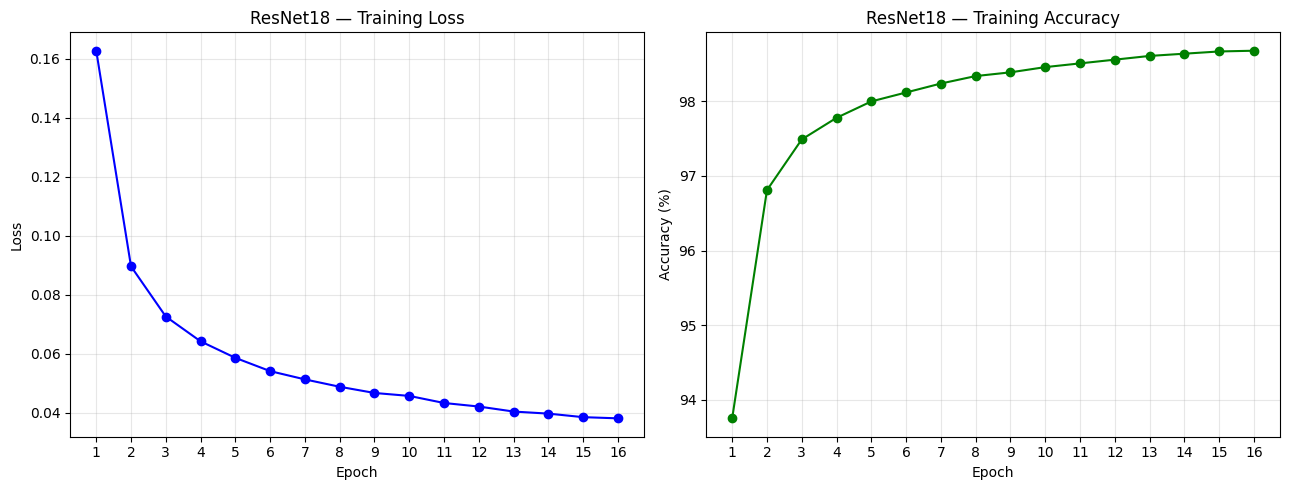

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training loss
axes[0].plot(epochs, train_loss, marker="o", color="blue")
axes[0].set_title("ResNet18 — Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(epochs)
axes[0].grid(True, alpha=0.3)

# Training accuracy
axes[1].plot(
    epochs,
    [x * 100 for x in train_accuracy],
    marker="o",
    color="green"
)
axes[1].set_title("ResNet18 — Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_xticks(epochs)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

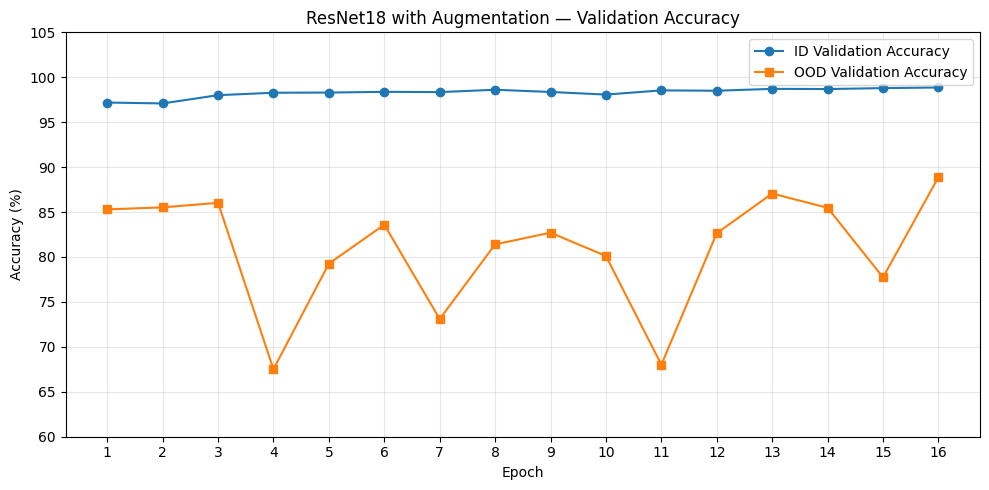

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    [x * 100 for x in id_val_accuracy],
    marker="o",
    label="ID Validation Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in ood_val_accuracy],
    marker="s",
    label="OOD Validation Accuracy"
)

plt.title("ResNet18 with Augmentation — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.ylim(60, 105)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Best Checkpoint: Training and Validation Metrics

The best OOD validation accuracy occurred at **epoch 16**.

| Metric | Result |
|---|---:|
| Best epoch | 16 |
| Training loss | 0.0381 |
| Training accuracy | 98.68% |
| ID validation accuracy | 98.86% |
| ID validation balanced accuracy | 98.86% |
| ID validation ROC-AUC | 0.9991 |
| OOD validation accuracy | 88.89% |
| OOD validation balanced accuracy | 88.89% |
| OOD validation ROC-AUC | 0.9592 |

The gap between ID and OOD validation performance indicates sensitivity to hospital-related distribution shifts.

### Official Test Performance

The best checkpoint (epoch 16) was evaluated on the **85,054-image** official Camelyon17-WILDS test split, using deterministic validation preprocessing and **no additional training**.

| Metric | Test result |
|---|---:|
| Test images | 85,054 |
| Accuracy | **81.16%** |
| Balanced accuracy | **81.16%** |
| ROC-AUC | **0.9451** |

The test accuracy was lower than the OOD validation accuracy (88.89%), while ROC-AUC remained high. These results indicate that discrimination and classification accuracy should both be considered when assessing generalization.

Results file: `resnet18_aug_test_results.json`.

### Summary of Accuracy Across Data Splits

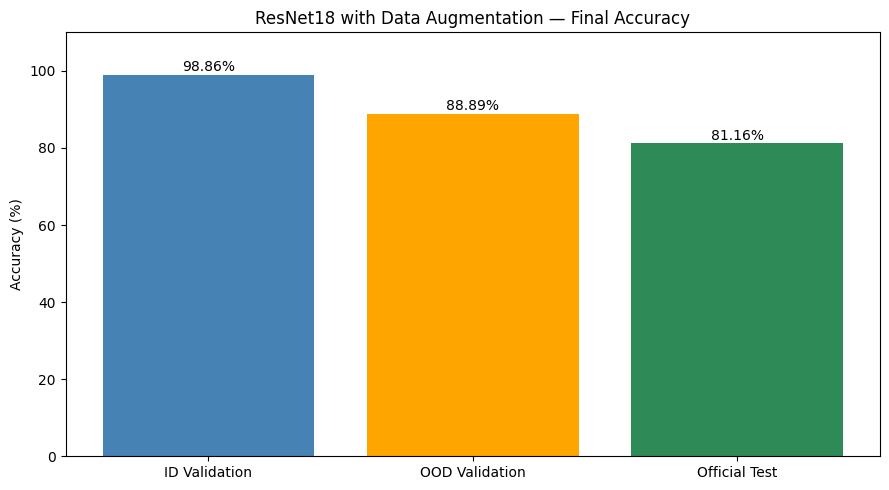

In [6]:
import matplotlib.pyplot as plt

datasets = ["ID Validation", "OOD Validation", "Official Test"]
accuracies = [98.86, 88.89, 81.16]

plt.figure(figsize=(9, 5))
bars = plt.bar(
    datasets,
    accuracies,
    color=["steelblue", "orange", "seagreen"]
)

plt.title("ResNet18 with Data Augmentation — Final Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

## Discussion and Conclusion

Training loss decreased from **0.1627 to 0.0381**, and training accuracy increased from **93.75% to 98.68%** over 16 epochs. ID validation accuracy remained consistently high, whereas OOD validation accuracy varied substantially between epochs. This variation illustrates the difficulty of obtaining stable performance under hospital-related domain shift.

The selected epoch-16 checkpoint achieved **98.86% ID validation accuracy**, **88.89% OOD validation accuracy**, and **81.16% official test accuracy**, with **0.9451 test ROC-AUC**. The decline in accuracy from validation to test highlights the need to assess generalization on held-out hospital data rather than relying on ID validation performance alone.

These findings describe the augmented ResNet18 experiment. Whether augmentation improves performance over the non-augmented ResNet18 baseline—and how ResNet18 compares with SmallCNN—will be evaluated in the **separate four-model comparison notebook**.